In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb

# ------------------------
# 1. Load datasets
# ------------------------
staffing_df = pd.read_csv(r"./datasets/staffing_train.csv")
bookings_df = pd.read_csv(r"./datasets/bookings_train.csv")

# Convert dates to datetime
staffing_df['date'] = pd.to_datetime(staffing_df['date'], dayfirst=True, errors='coerce')
bookings_df['appointment_date'] = pd.to_datetime(bookings_df['appointment_date'], dayfirst=True, errors='coerce')

# Task-section mapping
task_section_mapping = pd.DataFrame([
    ['TASK-001', 'SEC-001'], ['TASK-002', 'SEC-001'],
    ['TASK-003', 'SEC-002'], ['TASK-004', 'SEC-002'], ['TASK-005', 'SEC-002'], ['TASK-006', 'SEC-002'],
    ['TASK-007', 'SEC-003'], ['TASK-008', 'SEC-003'], ['TASK-009', 'SEC-003'],
    ['TASK-010', 'SEC-004'], ['TASK-011', 'SEC-004'], ['TASK-012', 'SEC-004'],
    ['TASK-013', 'SEC-005'], ['TASK-014', 'SEC-005'], ['TASK-015', 'SEC-005'],
    ['TASK-016', 'SEC-006'], ['TASK-017', 'SEC-006'], ['TASK-018', 'SEC-006'], ['TASK-019', 'SEC-006']
], columns=['task_id', 'section_id'])

bookings_df = bookings_df.merge(task_section_mapping, on='task_id', how='left')


In [2]:

# ------------------------
# 2. Precompute historical features
# ------------------------
staffing_df['day_of_week'] = staffing_df['date'].dt.dayofweek
staffing_df['month'] = staffing_df['date'].dt.month

# Total tasks per section per day
tasks_per_day = bookings_df.groupby(['section_id','appointment_date']).size().reset_index(name='total_tasks')
total_task_time = staffing_df[['section_id','date','total_task_time_minutes']]

# Historical mean total task time per weekday & section
avg_total_task_time_dow = staffing_df.groupby(['section_id','day_of_week'])['total_task_time_minutes'].mean().reset_index()
avg_total_task_time_dow.rename(columns={'total_task_time_minutes':'avg_total_task_time_dow'}, inplace=True)

# Historical mean number of tasks per weekday & section
tasks_per_day['day_of_week'] = tasks_per_day['appointment_date'].dt.dayofweek
avg_total_tasks_dow = tasks_per_day.groupby(['section_id','day_of_week'])['total_tasks'].mean().reset_index()
avg_total_tasks_dow.rename(columns={'total_tasks':'avg_total_tasks_dow'}, inplace=True)

# Historical mean employees per weekday & section
mean_employees_dow = staffing_df.groupby(['section_id','day_of_week'])['employees_on_duty'].mean().reset_index()
mean_employees_dow.rename(columns={'employees_on_duty':'mean_employees_dow'}, inplace=True)

# Rolling total task time per section
staffing_df = staffing_df.sort_values(['section_id','date'])
staffing_df['rolling_total_task_time'] = staffing_df.groupby('section_id')['total_task_time_minutes'].rolling(window=2, min_periods=1).mean().reset_index(0,drop=True)

# ------------------------
# 3. Merge historical features
# ------------------------
model_data = staffing_df.merge(avg_total_task_time_dow, on=['section_id','day_of_week'], how='left')
model_data = model_data.merge(avg_total_tasks_dow, on=['section_id','day_of_week'], how='left')
model_data = model_data.merge(mean_employees_dow, on=['section_id','day_of_week'], how='left')

# Keep only leakage-safe features
features = ['day_of_week','month','avg_total_task_time_dow','rolling_total_task_time',
            'mean_employees_dow','avg_total_tasks_dow']
X = model_data[features]
y = model_data['employees_on_duty']


MAE: 1.1726274387678333
RMSE: 1.6309694802520593
R2 Score: 0.6304734133677475


<Axes: title={'center': 'Feature Importance'}, xlabel='Importance score', ylabel='Features'>

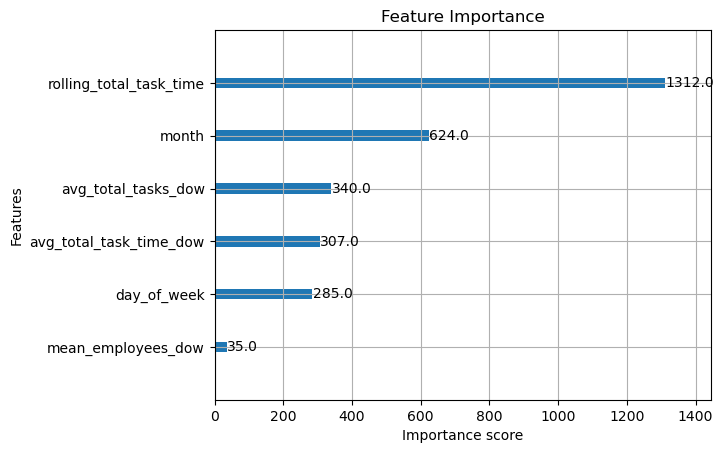

In [3]:

# ------------------------
# 4. Train/test split
# ------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ------------------------
# 5. Train XGBoost
# ------------------------
xgb_model = xgb.XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=4, random_state=42)
xgb_model.fit(X_train, y_train)

# ------------------------
# 6. Predict & evaluate
# ------------------------
y_pred = xgb_model.predict(X_test)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred, squared=False))
print("R2 Score:", r2_score(y_test, y_pred))

# Feature importance
xgb.plot_importance(xgb_model, importance_type='weight', max_num_features=10, title='Feature Importance')


In [4]:
# ------------------------
# Predict on training set
# ------------------------
y_train_pred = xgb_model.predict(X_train)

# Training metrics
train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = mean_squared_error(y_train, y_train_pred, squared=False)
train_r2 = r2_score(y_train, y_train_pred)

print("Training Set Metrics:")
print("MAE:", train_mae)
print("RMSE:", train_rmse)
print("R2 Score:", train_r2)

# ------------------------
# Predict on testing set
# ------------------------
y_test_pred = xgb_model.predict(X_test)

# Testing metrics
test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = mean_squared_error(y_test, y_test_pred, squared=False)
test_r2 = r2_score(y_test, y_test_pred)

print("\nTesting Set Metrics:")
print("MAE:", test_mae)
print("RMSE:", test_rmse)
print("R2 Score:", test_r2)


Training Set Metrics:
MAE: 0.9729083428940776
RMSE: 1.27155977557047
R2 Score: 0.7968373861533704

Testing Set Metrics:
MAE: 1.1726274387678333
RMSE: 1.6309694802520593
R2 Score: 0.6304734133677475


[I 2025-08-23 14:04:06,893] A new study created in memory with name: no-name-4060e55e-998b-4de4-86a8-6ec62bd616a6
[I 2025-08-23 14:04:07,373] Trial 0 finished with value: 0.7037197758882252 and parameters: {'n_estimators': 495, 'max_depth': 4, 'learning_rate': 0.11610932464932659, 'subsample': 0.99037164463852, 'colsample_bytree': 0.7776632938731564, 'gamma': 4.18083520362209, 'reg_alpha': 4.6892807354019, 'reg_lambda': 4.102363187798994}. Best is trial 0 with value: 0.7037197758882252.
[I 2025-08-23 14:04:07,918] Trial 1 finished with value: 0.6963893822963328 and parameters: {'n_estimators': 415, 'max_depth': 6, 'learning_rate': 0.10871071623326323, 'subsample': 0.8345536558778025, 'colsample_bytree': 0.9787882196342184, 'gamma': 2.5271333741887068, 'reg_alpha': 4.9205728150959835, 'reg_lambda': 2.465593966496446}. Best is trial 0 with value: 0.7037197758882252.
[I 2025-08-23 14:04:08,284] Trial 2 finished with value: 0.680075444384037 and parameters: {'n_estimators': 169, 'max_depth

Best parameters: {'n_estimators': 103, 'max_depth': 4, 'learning_rate': 0.10159170471842342, 'subsample': 0.9403417731997286, 'colsample_bytree': 0.8896479193651379, 'gamma': 4.684017893636096, 'reg_alpha': 4.93502602498949, 'reg_lambda': 4.288598598274451}
Best CV R2: 0.7067427941721788
Optuna-tuned XGBoost - Training Set Metrics:
MAE: 1.0786738287295485
RMSE: 1.4301649998526793
R2 Score: 0.7429944389977574

Optuna-tuned XGBoost - Testing Set Metrics:
MAE: 1.1447921665858647
RMSE: 1.5572582131950181
R2 Score: 0.6631199584939654


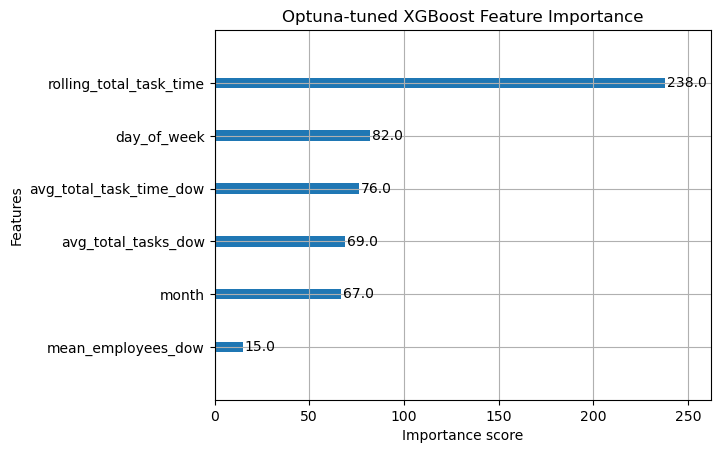

In [5]:
import optuna
import xgboost as xgb
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

# ------------------------
# 1. Train/test split (already done)
# ------------------------
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ------------------------
# 2. Optuna objective function
# ------------------------
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma': trial.suggest_float('gamma', 0.0, 5.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 5.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.0, 5.0),
        'random_state': 42
    }
    
    model = xgb.XGBRegressor(**params, objective='reg:squarederror')
    score = cross_val_score(model, X_train, y_train, cv=3, scoring='r2').mean()
    return score

# ------------------------
# 3. Create study and optimize
# ------------------------
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50)  # you can reduce/increase trials for speed/accuracy

print("Best parameters:", study.best_params)
print("Best CV R2:", study.best_value)

# ------------------------
# 4. Train final model with best parameters
# ------------------------
best_params = study.best_params
final_xgb = xgb.XGBRegressor(**best_params, objective='reg:squarederror')
final_xgb.fit(X_train, y_train)

# ------------------------
# 5. Predict & evaluate
# ------------------------
y_train_pred = final_xgb.predict(X_train)
y_test_pred = final_xgb.predict(X_test)

print("Optuna-tuned XGBoost - Training Set Metrics:")
print("MAE:", mean_absolute_error(y_train, y_train_pred))
print("RMSE:", mean_squared_error(y_train, y_train_pred, squared=False))
print("R2 Score:", r2_score(y_train, y_train_pred))

print("\nOptuna-tuned XGBoost - Testing Set Metrics:")
print("MAE:", mean_absolute_error(y_test, y_test_pred))
print("RMSE:", mean_squared_error(y_test, y_test_pred, squared=False))
print("R2 Score:", r2_score(y_test, y_test_pred))

# ------------------------
# 6. Feature importance
# ------------------------
xgb.plot_importance(final_xgb, max_num_features=10, importance_type='weight', title='Optuna-tuned XGBoost Feature Importance')
plt.show()
